# 04 · Buildings

Overture building footprints at tract level: counts and density, who supplied them, footprint quality, and how well the counts agree with independent building counts.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data").exists())
DATA, OUT, ANALYSIS = ROOT / "data", ROOT / "eda_outputs", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
df = pd.read_parquet(OUT / "base_table.parquet")

def box_by_region(ax, col, log=False, title="", ylabel=None, data=None):
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. How many buildings, and how dense?

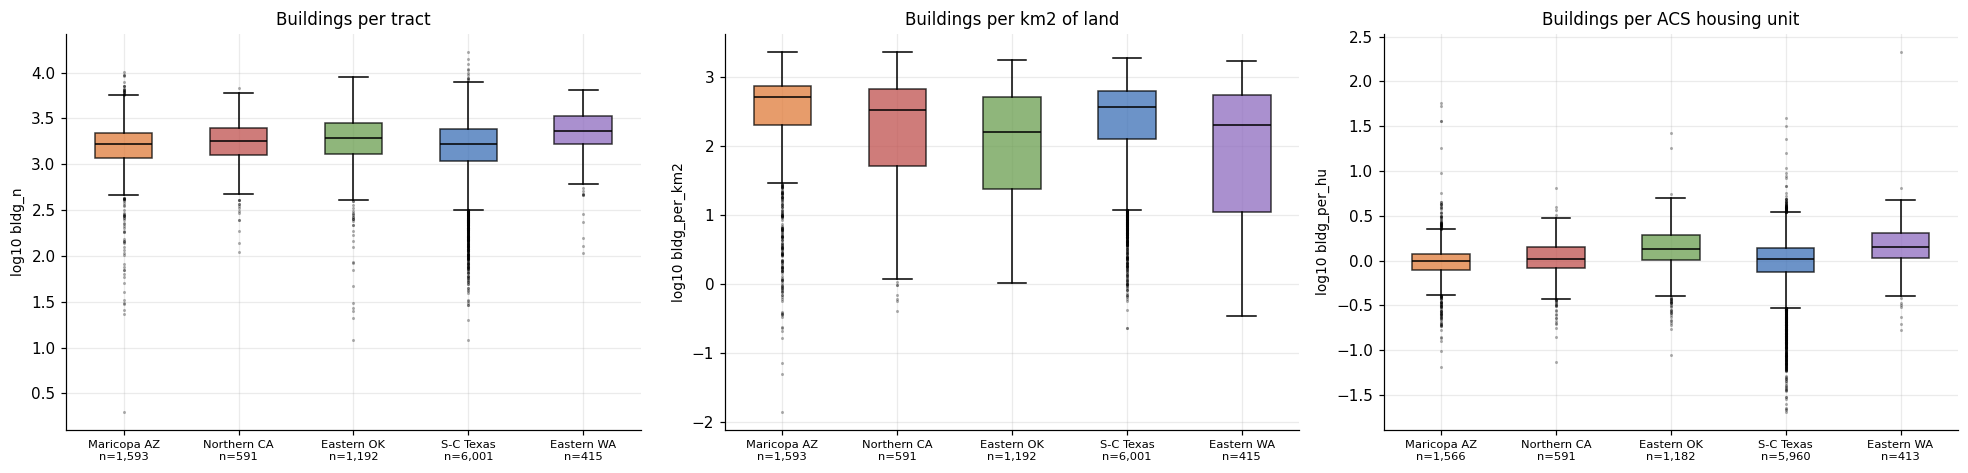

                  bldg_n  bldg_per_km2  bldg_per_hu
region                                             
maricopa-az       1646.0        507.46         0.98
northern-ca       1810.0        333.67         1.05
eastern-ok        1939.5        158.99         1.34
south-central-tx  1659.0        366.91         1.04
eastern-wa        2335.0        201.27         1.41
total buildings: 19,169,788 | Texas share: 59.8%


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4)); box_by_region(ax[0], "bldg_n", log=True, title="Buildings per tract"); box_by_region(ax[1], "bldg_per_km2", log=True, title="Buildings per km2 of land"); box_by_region(ax[2], "bldg_per_hu", log=True, title="Buildings per ACS housing unit")
plt.tight_layout(); plt.show()
print(df.groupby("region")[["bldg_n", "bldg_per_km2", "bldg_per_hu"]].median().reindex(REG).round(2).to_string()); print("total buildings:", f"{int(df.bldg_n.sum()):,}", "| Texas share:", f"{df[df.region == 'south-central-tx'].bldg_n.sum() / df.bldg_n.sum():.1%}")

**Takeaway:** there are 19.2 million buildings, 59.8% of them in Texas. The typical tract holds a similar number everywhere (median 1,646 to 2,335) because tracts are drawn around equal populations, but density differs about 3x, from 159 buildings/km2 in Eastern OK to 507 in Maricopa. Buildings per housing unit is about 1 in Maricopa (0.98) and Texas (1.04) but 1.34-1.41 in Eastern OK and Washington: rural tracts have more buildings than homes (outbuildings, sheds).

## 2. Where do the buildings come from?

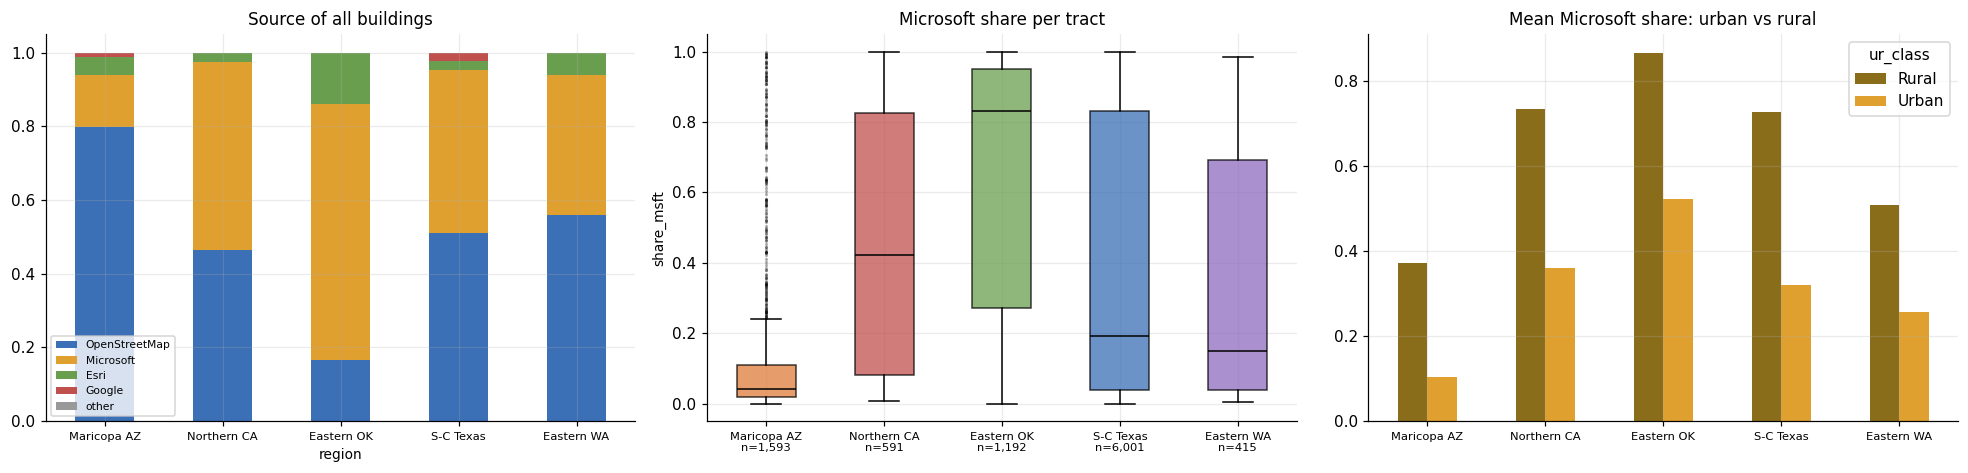

                  OpenStreetMap  Microsoft  Esri  Google  other
region                                                         
maricopa-az                0.80       0.14  0.05    0.01    0.0
northern-ca                0.47       0.51  0.03    0.00    0.0
eastern-ok                 0.17       0.69  0.14    0.00    0.0
south-central-tx           0.51       0.44  0.02    0.02    0.0
eastern-wa                 0.56       0.38  0.06    0.00    0.0

ur_class          Rural  Urban
region                        
maricopa-az        0.37   0.10
northern-ca        0.73   0.36
eastern-ok         0.87   0.52
south-central-tx   0.73   0.32
eastern-wa         0.51   0.26


In [3]:
src = ["bldg_n_osm", "bldg_n_msft", "bldg_n_esri", "bldg_n_google", "bldg_n_other"]; lab = ["OpenStreetMap", "Microsoft", "Esri", "Google", "other"]
mix = df.groupby("region")[src].sum().div(df.groupby("region").bldg_n.sum(), axis=0).reindex(REG); mix.columns = lab
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4)); mix.plot.bar(stacked=True, ax=ax[0], rot=0, color=["#3b6fb6", "#e0a030", "#6a9e4f", "#c0504d", "#999"]); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[0].set_title("Source of all buildings"); ax[0].legend(fontsize=7)
box_by_region(ax[1], "share_msft", title="Microsoft share per tract")
ur = df.pivot_table(index="region", columns="ur_class", values="share_msft", aggfunc="mean").reindex(REG); ur.plot.bar(ax=ax[2], rot=0, color=["#8a6d1a", "#e0a030"]); ax[2].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[2].set_title("Mean Microsoft share: urban vs rural"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show(); print(mix.round(2).to_string()); print(); print(ur.round(2).to_string())

**Takeaway:** the building source differs sharply by region: OSM supplies 80% in Maricopa, Microsoft 69% in Eastern OK (Esri another 14%) and about half in Northern CA and Texas. In every region rural tracts rely on Microsoft far more than urban ones (Eastern OK 0.87 vs 0.52, Northern CA 0.73 vs 0.36, Maricopa 0.37 vs 0.10). The challenge's building reference is Microsoft footprints, so in rural tracts Overture already contains much of it.

## 3. Footprint size and attribute quality

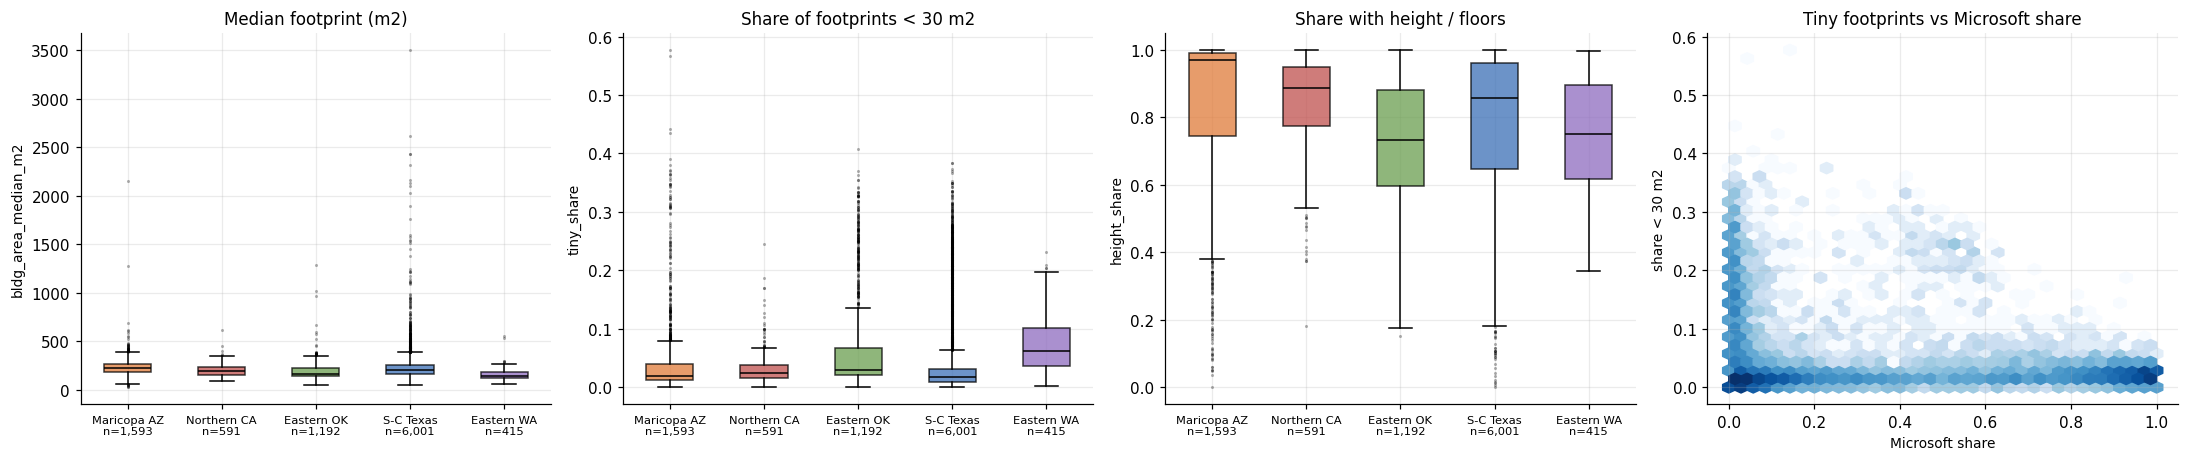

                  bldg_area_median_m2  tiny_share  height_share
region                                                         
maricopa-az                   221.775       0.020         0.970
northern-ca                   195.570       0.025         0.887
eastern-ok                    166.490       0.029         0.735
south-central-tx              202.458       0.017         0.858
eastern-wa                    141.603       0.062         0.750
Spearman(msft share, tiny share) = -0.03


In [4]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.3)); box_by_region(ax[0], "bldg_area_median_m2", title="Median footprint (m2)"); box_by_region(ax[1], "tiny_share", title="Share of footprints < 30 m2"); box_by_region(ax[2], "height_share", title="Share with height / floors")
ax[3].hexbin(df.share_msft, df.tiny_share, gridsize=35, cmap="Blues", mincnt=1, bins="log"); ax[3].set(xlabel="Microsoft share", ylabel="share < 30 m2", title="Tiny footprints vs Microsoft share")
plt.tight_layout(); plt.show(); print(df.groupby("region")[["bldg_area_median_m2", "tiny_share", "height_share"]].median().reindex(REG).round(3).to_string()); print("Spearman(msft share, tiny share) =", round(stats.spearmanr(df.share_msft, df.tiny_share, nan_policy="omit")[0], 2))

**Takeaway:** median footprint is 142 m2 in Eastern WA up to 222 m2 in Maricopa, and Eastern WA has the most tiny polygons (6.2% under 30 m2 vs 1.7-2.9% elsewhere). Height or floor data is nearly complete in Maricopa (median share 0.97) but only about 0.74-0.75 in Eastern OK and Eastern WA. Tiny-polygon share is unrelated to the Microsoft share (Spearman -0.03).

## 4. Do our building counts match independent counts?
A building gap is only possible where Overture has *fewer* buildings than a reference, so the ratio to each reference matters.

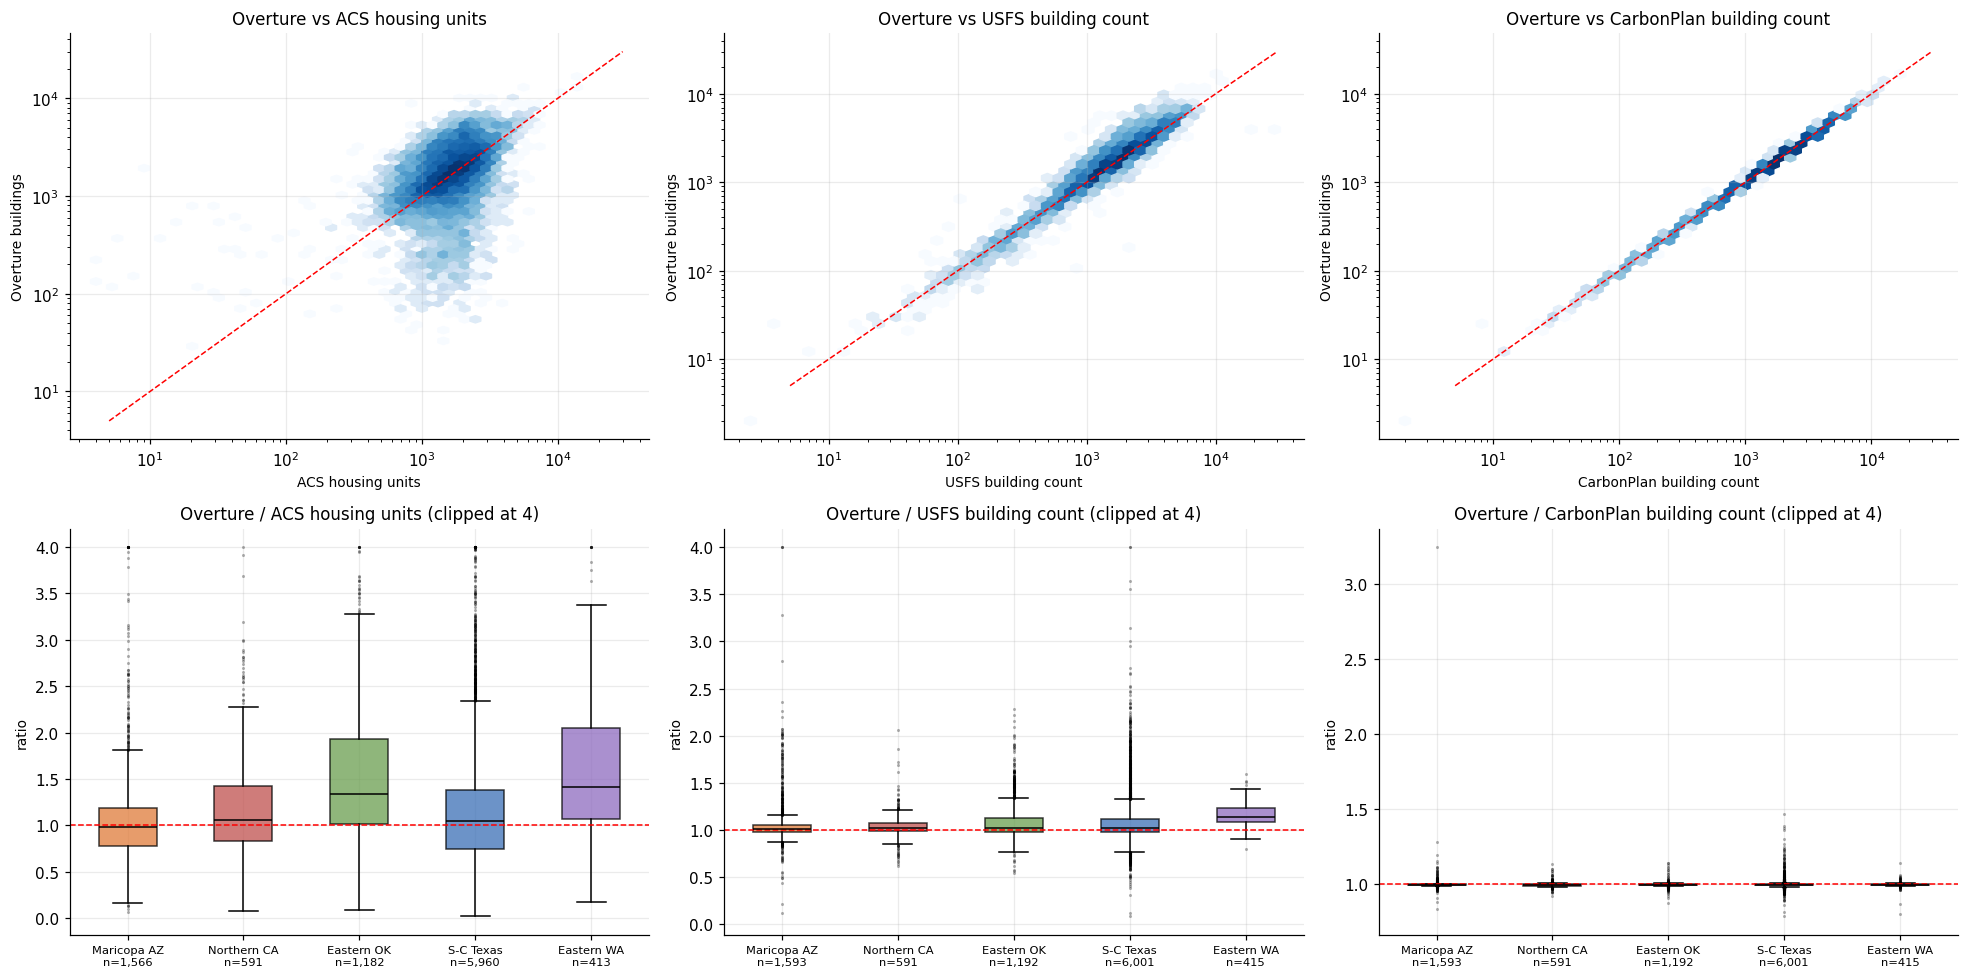

                reference  Spearman  median ratio  % tracts ratio < 1  % ratio < 0.5
        ACS housing units     0.469         1.067              42.659         10.626
      USFS building count     0.956         1.021              35.917          0.143
CarbonPlan building count     1.000         0.998              65.707          0.000

% of tracts with ratio < 1, by region:
                  ACS housing units  USFS building count  CarbonPlan building count
region                                                                             
maricopa-az                    53.0                 40.0                       57.0
northern-ca                    43.0                 34.0                       68.0
eastern-ok                     24.0                 35.0                       71.0
south-central-tx               45.0                 37.0                       67.0
eastern-wa                     20.0                  3.0                       67.0


In [5]:
ref = {"housing_units": "ACS housing units", "usfs_BuildingCount_sum": "USFS building count", "carbonplan_buildings": "CarbonPlan building count"}
fig, ax = plt.subplots(2, 3, figsize=(18, 9)); rows = []
for j, (c, nm) in enumerate(ref.items()):
    d = df[(df[c] > 0) & (df.bldg_n > 0)]; ax[0, j].hexbin(d[c], d.bldg_n, gridsize=45, xscale="log", yscale="log", cmap="Blues", mincnt=1, bins="log"); ax[0, j].plot([5, 3e4], [5, 3e4], "r--", lw=1); ax[0, j].set(xlabel=nm, ylabel="Overture buildings", title=f"Overture vs {nm}")
    ratio = (d.bldg_n / d[c]); dd = d.assign(ratio=ratio.clip(upper=4)); box_by_region(ax[1, j], "ratio", data=dd, title=f"Overture / {nm} (clipped at 4)"); ax[1, j].axhline(1, color="r", ls="--", lw=1)
    rows.append((nm, stats.spearmanr(d[c], d.bldg_n)[0], ratio.median(), (ratio < 1).mean() * 100, (ratio < .5).mean() * 100))
plt.tight_layout(); plt.show(); print(pd.DataFrame(rows, columns=["reference", "Spearman", "median ratio", "% tracts ratio < 1", "% ratio < 0.5"]).round(3).to_string(index=False))
sh = pd.DataFrame({nm: df[df[c] > 0].groupby("region").apply(lambda g, c=c: (g.bldg_n / g[c] < 1).mean() * 100) for c, nm in ref.items()}).reindex(REG); print("\n% of tracts with ratio < 1, by region:"); print(sh.round(0).to_string())

**Takeaway:** against ACS housing units Overture's count is only moderately correlated (Spearman 0.47, median ratio 1.07, below 1 in 43% of tracts, from 20% in Eastern WA to 53% in Maricopa). Against the USFS building count it tracks closely (0.96, ratio 1.02, below 1 in 36% of tracts, but below 0.5 in only 0.1%; by region 3% in Eastern WA to 40% in Maricopa). CarbonPlan is a copy of Overture's own count (Spearman 1.000, ratio 0.998), so its 66% of tracts 'below 1' is rounding, not a gap. If the hidden building gap is built from an independent count, small shortfalls would be common, large ones rare, and Maricopa would likely carry the most.

## 5. Map of building density and sources

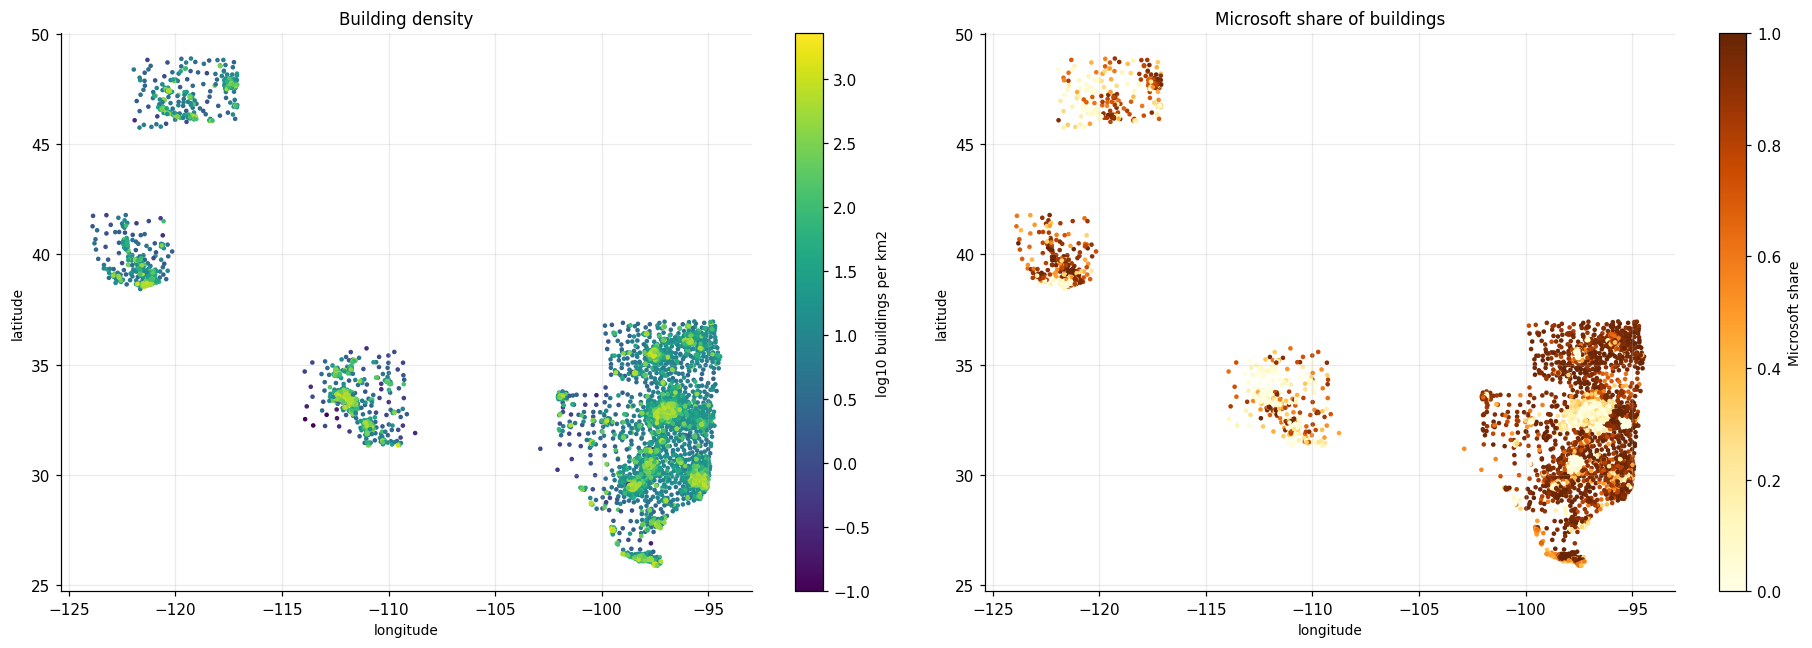

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sc = ax[0].scatter(df.INTPTLON, df.INTPTLAT, c=np.log10(df.bldg_per_km2.clip(lower=.1)), s=4, cmap="viridis"); plt.colorbar(sc, ax=ax[0], label="log10 buildings per km2"); ax[0].set_title("Building density")
sc = ax[1].scatter(df.INTPTLON, df.INTPTLAT, c=df.share_msft, s=4, cmap="YlOrBr"); plt.colorbar(sc, ax=ax[1], label="Microsoft share"); ax[1].set_title("Microsoft share of buildings")
for a in ax: a.set(xlabel="longitude", ylabel="latitude")
plt.tight_layout(); plt.show()

**Takeaway:** building density follows the metro areas (the bright clusters in Phoenix, the Texas cities and the California and Washington valleys), and the Microsoft share is the mirror image: low in city cores, high in the rural tracts between them. Density and source mix are both spatially structured, so neighbouring tracts look alike on the map (not formally tested here).